# 03. Облегченный мультимодальный контур предупреждения: финальная AIOps-архитектура

В `01_eda.ipynb` данные были изучены как предмет исследования: workload оказались неоднородными, модальности были неполными, target имели разную плотность, а ранний warning выглядел шумным. В `02_baseline_pipeline.ipynb` на основе этих наблюдений был собран protocol-fixed pipeline: strict contract, `stratified_by_workload`, target matrix, validation threshold и минимальный baseline как smoke test.

В этом notebook фокус меняется. Теперь центральный объект - финальный облегченный мультимодальный контур предупреждения. Мы строим и объясняем его архитектуру, фиксируем режим обучения, проверяем manifest и checkpoint, смотрим training dynamics, сравниваем с baseline на том же протоколе и принимаем исследовательское решение: где мультимодальный контур действительно оправдывает сложность, а где простой baseline остается сильнее.

Ключевой критерий здесь не “победить все числа”. Для AIOps раннее предупреждение полезно только тогда, когда оно не превращается в поток ложных тревог и может работать в ограниченном runtime. Поэтому ценность финального контура оценивается сразу в нескольких слоях: window-level, error-level, alert-level и system-level.


In [1]:
EXECUTION_MODE = "train_from_scratch"
REQUIRE_INT8_EXPORT = True
ALLOWED_EXECUTION_MODES = {"train_from_scratch", "reproduce_from_manifest", "smoke_test"}

In [2]:
from __future__ import annotations

import importlib.util
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import precision_recall_curve

PROJECT_ROOT = Path.cwd()
CONTRACT_PATH = PROJECT_ROOT / "dashboard" / "artifacts" / "contract" / "strict_intensity_contract.csv.gz"
MODEL_DIR = PROJECT_ROOT / "dashboard" / "artifacts" / "model" / "protocol_fixed_efficient_hades"
RUN_ROOT = PROJECT_ROOT / "dashboard" / "artifacts" / "model_runs" / "protocol_fixed_hades"
BUNDLE_DIR = PROJECT_ROOT / "dashboard" / "artifacts" / "bundle"
BASELINE_DIR = PROJECT_ROOT / "dashboard" / "artifacts" / "reports" / "protocol_fixed_baselines"

EXPERIMENT_CONFIG = {
    "run_id": "final_protocol_fixed_hades",
    "split_protocol": "stratified_by_workload",
    "variant": "efficient_hades",
    "modern_log_backend": "embeddinggemma",
    "embeddinggemma_model": "google/embeddinggemma-300m",
    "seed": 43,
    "targets": ["y_warning", "horizon_30s", "horizon_60s", "horizon_120s", "horizon_300s"],
    "monitor_target": "horizon_60s",
    "alert_target": "horizon_60s",
    "train_monitor": "fp_budget_f1",
    "normalization": "workload_norm",
    "metric_feature_mode": "raw_plus_deviation",
    "epochs": 30,
    "patience": 8,
    "batch_size": 128,
    "fp_budget": 0.10,
    "validation_seed": 43,
    "device": "cuda",
    "quantization": "dynamic",
}

DISPLAY_TARGETS = ["y_warning", "horizon_30s", "horizon_60s", "horizon_120s", "horizon_300s"]

TARGET_LABELS = {
    "y_warning": "Горизонт 180 с",
    "horizon_30s": "Горизонт 30 с",
    "horizon_60s": "Горизонт 60 с",
    "horizon_120s": "Горизонт 120 с",
    "horizon_300s": "Горизонт 300 с",
}

PALETTE = {
    "blue": "#2F6F9F",
    "teal": "#2A9D8F",
    "green": "#5A8F3C",
    "orange": "#D98032",
    "red": "#B84A4A",
    "gray": "#6E7781",
    "light_gray": "#D8DEE4",
}

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.titleweight": "bold",
    }
)


def run_command(cmd: list[str]) -> None:
    result = subprocess.run(cmd, cwd=PROJECT_ROOT, text=True, capture_output=True)
    if result.stdout:
        print(result.stdout)
    if result.returncode != 0:
        if result.stderr:
            print(result.stderr)
        raise RuntimeError(f"Command failed: {' '.join(cmd)}")


def read_csv(path: Path) -> pd.DataFrame:
    if not path.exists():
        return pd.DataFrame()
    return pd.read_csv(path, low_memory=False)


def read_json(path: Path, default=None):
    if default is None:
        default = {}
    if not path.exists():
        return default
    return json.loads(path.read_text(encoding="utf-8"))


def label_target(name: str) -> str:
    return TARGET_LABELS.get(str(name), str(name))


def numeric(frame: pd.DataFrame, cols: list[str] | None = None) -> pd.DataFrame:
    out = frame.copy()
    if cols is None:
        cols = [
            "seed",
            "n",
            "positives",
            "prevalence",
            "average_precision",
            "roc_auc",
            "precision",
            "recall",
            "f1",
            "false_positives",
            "missed_anomalies",
            "threshold",
            "train_selected_epoch",
            "train_monitor_value",
            "torch_latency_ms_per_sample",
        ]
    for col in cols:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    return out


def module_status(names: list[str]) -> pd.DataFrame:
    rows = []
    for name in names:
        spec = importlib.util.find_spec(name)
        version = "missing"
        if spec is not None:
            try:
                module = __import__(name)
                version = str(getattr(module, "__version__", "installed"))
            except Exception as exc:
                version = f"import failed: {type(exc).__name__}: {exc}"
        rows.append({"module": name, "status": "OK" if spec is not None else "MISSING", "version": version})
    return pd.DataFrame(rows)


def assert_runtime_dependencies() -> None:
    deps = module_status(["onnx", "onnxruntime", "sentence_transformers", "huggingface_hub"])
    missing = deps.loc[deps["status"].eq("MISSING"), "module"].tolist()
    display(deps.style.hide(axis="index"))
    if REQUIRE_INT8_EXPORT and missing:
        raise RuntimeError(
            "Для train_from_scratch с EmbeddingGemma и INT8 export нужны зависимости: "
            + ", ".join(missing)
            + ". Установить: pip install onnx onnxruntime sentence-transformers huggingface-hub"
        )


def build_training_command() -> list[str]:
    return [
        sys.executable,
        "-m",
        "dashboard.training.final_model",
        "--run-id",
        EXPERIMENT_CONFIG["run_id"],
        "--contract-path",
        str(CONTRACT_PATH),
        "--run-root",
        str(RUN_ROOT),
        "--model-out-dir",
        str(MODEL_DIR),
        "--bundle-out-dir",
        str(BUNDLE_DIR),
        "--device",
        EXPERIMENT_CONFIG["device"],
        "--split-protocol",
        EXPERIMENT_CONFIG["split_protocol"],
        "--variant",
        EXPERIMENT_CONFIG["variant"],
        "--modern-log-backend",
        EXPERIMENT_CONFIG["modern_log_backend"],
        "--embeddinggemma-model",
        EXPERIMENT_CONFIG["embeddinggemma_model"],
        "--seed",
        str(EXPERIMENT_CONFIG["seed"]),
        "--monitor-target",
        EXPERIMENT_CONFIG["monitor_target"],
        "--alert-target",
        EXPERIMENT_CONFIG["alert_target"],
        "--normalization",
        EXPERIMENT_CONFIG["normalization"],
        "--metric-feature-mode",
        EXPERIMENT_CONFIG["metric_feature_mode"],
        "--epochs",
        str(EXPERIMENT_CONFIG["epochs"]),
        "--batch-size",
        str(EXPERIMENT_CONFIG["batch_size"]),
        "--patience",
        str(EXPERIMENT_CONFIG["patience"]),
        "--fp-budget",
        str(EXPERIMENT_CONFIG["fp_budget"]),
        "--validation-seed",
        str(EXPERIMENT_CONFIG["validation_seed"]),
        "--train-monitor",
        EXPERIMENT_CONFIG["train_monitor"],
        "--quantization",
        EXPERIMENT_CONFIG["quantization"],
    ]


def format_command(cmd: list[str]) -> str:
    return (" " + "\\" + "\n  ").join(cmd)


def select_log_manifest(feature_manifest: dict, run_config: dict) -> dict:
    log_block = feature_manifest.get("log", {}) if isinstance(feature_manifest, dict) else {}
    backend = run_config.get("modern_log_backend", EXPERIMENT_CONFIG.get("modern_log_backend", "embeddinggemma"))
    if isinstance(log_block, dict) and backend in log_block:
        return log_block.get(backend, {})
    if isinstance(log_block, dict) and "embeddinggemma" in log_block:
        return log_block.get("embeddinggemma", {})
    if isinstance(log_block, dict) and log_block:
        return next(iter(log_block.values()))
    return {}


def refresh_artifact_metadata() -> None:
    global run_config, feature_manifest_all, feature_manifest, metric_manifest, log_manifest, embedding_manifest
    run_config = read_json(MODEL_DIR / "run_config.json")
    feature_manifest_all = read_json(MODEL_DIR / "feature_manifest.json")
    feature_manifest = feature_manifest_all.get(EXPERIMENT_CONFIG["split_protocol"], {})
    metric_manifest = feature_manifest.get("metric", {})
    log_manifest = select_log_manifest(feature_manifest, run_config)
    embedding_manifest = log_manifest.get("embedding", {})


if EXECUTION_MODE not in ALLOWED_EXECUTION_MODES:
    raise ValueError(f"Unsupported EXECUTION_MODE={EXECUTION_MODE!r}")

## 1. Что именно должна исправить финальная модель

Baseline из `02` выполнил свою роль: pipeline оказался рабочим, а данные действительно содержали сигнал. Но baseline также показал ограничения простого подхода. Длинный горизонт `horizon_300s` хорошо ловился KPI-признаками, а `warning/anomaly` неплохо поддерживались логами, но короткие горизонты оставались шумными. На `horizon_60s` простой fused baseline давал F1 около 0.466 и 172 FP; на `horizon_30s` precision был около 0.186.

Поэтому финальный облегченный мультимодальный контур предупреждения здесь нужен не как “более большая модель”, а как попытка собрать более осмысленный мультимодальный контур: отдельно обработать logs и KPI, дать им обменяться информацией через fusion, предсказывать несколько heads одновременно и затем переводить score в alert-level решение с контролем ложных тревог.


In [3]:
baseline_lessons = pd.DataFrame(
    [
        (
            "Простое fused-склеивание не решило ранний warning",
            "отдельные ветки logs/KPI и cross-modal attention",
            "модель должна учить взаимодействие модальностей, а не только объединять признаки",
        ),
        (
            "`horizon_60s` важен, но шумный",
            "monitor target = horizon_60s, monitor metric = fp_budget_f1",
            "checkpoint выбирается не по train loss, а по validation warning-поведению",
        ),
        (
            "FP критичны для AIOps",
            "сохраняем validation_best_f1 и validation_fp_budget policy",
            "качество оценивается вместе с FP/FN, а не только F1",
        ),
        (
            "KPI имеют workload shift",
            "workload_norm + raw_plus_deviation",
            "модель получает и уровень, и отклонение от привычного поведения",
        ),
        (
            "Модель должна жить в runtime",
            "ограниченные размерности, shallow encoders, reserved INT8/ONNX path",
            "финальный контур должен быть пригоден к inference на слабом железе",
        ),
    ],
    columns=["Что стало ясно после 02", "Решение в финальном контуре", "Смысл для AIOps"],
)
display(baseline_lessons.style.hide(axis="index"))


Что стало ясно после 02,Решение в финальном контуре,Смысл для AIOps
Простое fused-склеивание не решило ранний warning,отдельные ветки logs/KPI и cross-modal attention,"модель должна учить взаимодействие модальностей, а не только объединять признаки"
"`horizon_60s` важен, но шумный","monitor target = horizon_60s, monitor metric = fp_budget_f1","checkpoint выбирается не по train loss, а по validation warning-поведению"
FP критичны для AIOps,сохраняем validation_best_f1 и validation_fp_budget policy,"качество оценивается вместе с FP/FN, а не только F1"
KPI имеют workload shift,workload_norm + raw_plus_deviation,"модель получает и уровень, и отклонение от привычного поведения"
Модель должна жить в runtime,"ограниченные размерности, shallow encoders, reserved INT8/ONNX path",финальный контур должен быть пригоден к inference на слабом железе


Эта таблица задает рамку для всего notebook. Мы не пытаемся доказать, что финальный контур должен быть лучше baseline по всем target. Мы проверяем более узкую и более прикладную гипотезу: дает ли структурированная мультимодальная модель полезный выигрыш там, где baseline был шумным, и снижает ли она ложные тревоги без разрушения всего warning-смысла.


## 2. Архитектура облегченного мультимодального контура

Облегченный мультимодальный контур предупреждения строится вокруг двух разных источников данных. Logs описывают событийный контекст: какие шаблоны сообщений появились в окне, какие фрагменты повторяются перед деградацией и насколько окно заполнено логовыми событиями. KPI описывают числовую динамику: как менялись CPU, disk, memory, network и системные счетчики в сегменте времени. Если просто склеить эти признаки в одну таблицу, модель не различает роли источников. Поэтому в финальном контуре каждая модальность сначала проходит через свою ветку, а fusion происходит уже на уровне представлений.

Упрощенная логика такая: log-фрагменты заранее кодируются offline encoder `google/embeddinggemma-300m` и сохраняются как dense cached embeddings для каждого выбранного события окна. KPI превращаются во временной сегмент выбранных каналов с workload-aware normalization и deviation-признаками. Затем две ветки обмениваются информацией через cross-modal attention. Финальное представление содержит не только `log_repr` и `metric_repr`, но и их разность и произведение: это помогает модели видеть согласие/расхождение между модальностями. После этого несколько heads одновременно предсказывают warning, risk, anomaly и горизонты раннего предупреждения.


In [ ]:
run_config = read_json(MODEL_DIR / "run_config.json")
feature_manifest_all = read_json(MODEL_DIR / "feature_manifest.json")
feature_manifest = feature_manifest_all.get(EXPERIMENT_CONFIG["split_protocol"], {})
metric_manifest = feature_manifest.get("metric", {})
log_manifest = select_log_manifest(feature_manifest, run_config)
embedding_manifest = log_manifest.get("embedding", {})

architecture_table = pd.DataFrame(
    [
        (
            "Логовый энкодер",
            f"{run_config.get('max_log_events', 32)} событий x {run_config.get('log_embedding_dim', 128)} dim",
            "Transformer-ветка",
            "событийный контекст окна",
        ),
        (
            "KPI-энкодер",
            f"{metric_manifest.get('segment_len', 64)} шагов x {metric_manifest.get('input_dim', 323)} признака",
            "компактная metric-ветка (TinyTimeMixer-like)",
            "числовая динамика и отклонения KPI",
        ),
        (
            "Маски доступности",
            "log_mask / metric_mask",
            "masked pooling",
            "устойчивость к пустым логам и неполным KPI-сегментам",
        ),
        (
            "Кросс-модальное слияние",
            "log_repr + metric_repr",
            "двунаправленное внимание",
            "взаимодействие событий и метрик",
        ),
        (
            "Общее представление окна",
            "[log, metric, |diff|, product]",
            "MLP",
            "единое состояние окна",
        ),
        (
            "Multi-head выход",
            ", ".join(label_target(t) for t in DISPLAY_TARGETS),
            "целевые головы для сравнения",
            "один инференс для нескольких каналов предупреждения",
        ),
        (
            "Пороговый и alert-слой",
            "оценки validation + последовательность окон",
            "вне нейросети",
            "перевод score в события предупреждения",
        ),
    ],
    columns=["Компонент", "Вход", "Механизм", "Роль"],
)
display(architecture_table.style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(13.2, 5.6))
ax.axis("off")

boxes = [
    (0.03, 0.52, 0.15, 0.18, "Strict contract\nокна + целевые каналы", PALETTE["light_gray"]),
    (0.25, 0.72, 0.17, 0.16, "Логи\nшаблоны + эмбеддинги", "#F7D9B7"),
    (0.25, 0.30, 0.17, 0.16, "KPI-сегменты\nworkload-нормировка + отклонения", "#CFE2F3"),
    (0.50, 0.72, 0.16, 0.16, "Логовый энкодер\nTransformer", "#F4B183"),
    (0.50, 0.30, 0.16, 0.16, "KPI-энкодер\nTiny mixer", "#9DC3E6"),
    (0.73, 0.51, 0.16, 0.18, "Кросс-модальное слияние\nвнимание + взаимодействия", "#B7E1CD"),
    (0.93, 0.51, 0.12, 0.18, "Multi-head\nоценки каналов", "#D9D2E9"),
]

for x, y, w, h, text, color in boxes:
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=color, edgecolor="#404040", linewidth=1.0))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9)

arrows = [
    ((0.18, 0.61), (0.25, 0.80)),
    ((0.18, 0.61), (0.25, 0.38)),
    ((0.42, 0.80), (0.50, 0.80)),
    ((0.42, 0.38), (0.50, 0.38)),
    ((0.66, 0.80), (0.73, 0.62)),
    ((0.66, 0.38), (0.73, 0.58)),
    ((0.89, 0.60), (0.93, 0.60)),
]
for start, end in arrows:
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", lw=1.4, color="#404040"))

ax.text(0.50, 0.08, "Пороги выбираются на validation; alert-layer работает поверх последовательности окон", ha="center", fontsize=10, color="#333333")
plt.tight_layout()
plt.show()


На схеме важно разделение ответственности. Нейросеть выдает score по нескольким heads, но не объявляет инцидент сама по себе. Threshold-layer переводит score в бинарное решение на уровне окна, а alert-layer уже решает, когда последовательность окон становится предупреждением. Это сохраняет главный AIOps-принцип работы: score модели, состояние alert-layer и факт incident не смешиваются.

Архитектура также объясняет слово `Efficient`. Тяжелый языковой encoder не входит в обучаемый PyTorch-граф и не запускается на каждом кадре dashboard. EmbeddingGemma используется заранее, на этапе preprocessing/export, чтобы превратить логовые шаблоны в cached dense embeddings. Дальше inference работает с готовыми векторами; KPI ограничены 64 выбранными каналами, `d_model=128`, log branch имеет 1 слой, metric branch - 2 слоя. Поэтому финальная модель должна быть не только точнее или аккуратнее baseline, но и пригоднее для запуска вне большой GPU-машины.


## 3. Режимы запуска notebook

Notebook поддерживает три режима. `reproduce_from_manifest` восстанавливает исследовательский отчет из уже сохраненного manifest/checkpoint. `smoke_test` нужен для быстрой проверки архитектуры и схем без тяжелого обучения. Полный запуск делается через `train_from_scratch`: notebook вызывает `dashboard.training.final_model`, обучает финальный облегченный мультимодальный контур предупреждения, экспортирует bundle и пытается создать ONNX/INT8 runtime-файлы.

Чтобы запустить обучение на CUDA-машине, в первой code-ячейке нужно поменять только одну строку:

```python
EXECUTION_MODE = "train_from_scratch"
```

После этого выполнить `Run All`. Перед стартом должны импортироваться `sentence_transformers`, `huggingface_hub`, `onnx` и `onnxruntime`: первые два пакета нужны для расчета EmbeddingGemma-cache, вторые два - для ONNX/INT8 export. Если зависимость отсутствует, notebook остановится до тяжелого обучения и прямо скажет, какой пакет поставить.


In [ ]:
mode_table = pd.DataFrame(
    [
        ("train_from_scratch", "обучить модель, экспортировать bundle и ONNX/INT8", "полный пересчет на CUDA-машине"),
        ("reproduce_from_manifest", "восстановить отчет из manifest/checkpoint", "основной режим чтения ВКР"),
        ("smoke_test", "проверить forward pass и схемы без обучения", "быстрая проверка notebook"),
    ],
    columns=["Режим", "Что делает", "Когда нужен"],
)
display(mode_table.style.hide(axis="index"))

training_command = build_training_command()
print("Текущий EXECUTION_MODE:", EXECUTION_MODE)

if EXECUTION_MODE == "train_from_scratch":
    assert_runtime_dependencies()
    run_command(training_command)
    refresh_artifact_metadata()
    print("Training finished. Artifacts were refreshed from MODEL_DIR and BUNDLE_DIR.")
elif EXECUTION_MODE == "smoke_test":
    print("Smoke mode: heavy training is skipped; architecture and artifact checks will run below.")
else:
    print("Reproduce mode: using saved manifest, checkpoint and metrics.")


В текущем режиме notebook читает сохраненный manifest. Это не означает, что обучение “выключено”: параметры запуска, история по epoch, checkpoint, thresholds, тестовые метрики и runtime-слоты берутся из сохраненных artifacts. Если переключить `EXECUTION_MODE` на `train_from_scratch`, эта же страница становится оркестратором полного training/export цикла.

Для ONNX/INT8 важна отдельная проверка. Качество модели оценивается по Torch checkpoint, а ONNX/INT8 рассматривается как runtime-режим для слабого CPU-only железа. Поэтому после полного запуска ожидаются три promoted-файла:

```text
dashboard/artifacts/model/protocol_fixed_efficient_hades/model.pt
dashboard/artifacts/model/protocol_fixed_efficient_hades/model.onnx
dashboard/artifacts/model/protocol_fixed_efficient_hades/model.int8.onnx
```


## 4. Training protocol и manifest

Перед метриками фиксируем протокол обучения. Это нужно не для формальности, а чтобы понять, какой именно эксперимент сравнивается с baseline из `02`. Особенно важны `monitor_target=horizon_60s` и `train_monitor=fp_budget_f1`: checkpoint выбирается по раннему warning при ограничении FP, а не по последней эпохе и не по test.

В этом же протоколе фиксируется runtime-часть. `--quantization dynamic` не меняет исследовательскую модель и не должен улучшать F1; он нужен, чтобы после обучения получить облегченный ONNX/INT8 inference artifact и проверить пригодность контура для ноутбука/CPU-only запуска.


In [ ]:
train_manifest = read_json(MODEL_DIR / "train_manifest.json", default=[])
final_training_manifest = read_json(MODEL_DIR / "final_training_manifest.json")
model_manifest = read_json(MODEL_DIR / "protocol_fixed_model_manifest.json")
runtime_report = final_training_manifest.get("export_report", {}).get("runtime", {}) or model_manifest.get("runtime", {})

protocol_rows = [
    ("Run id", run_config.get("run_id", EXPERIMENT_CONFIG["run_id"])),
    ("Split protocol", ", ".join(run_config.get("split_protocols", [EXPERIMENT_CONFIG["split_protocol"]]))),
    ("Variant", ", ".join(run_config.get("variants", [EXPERIMENT_CONFIG["variant"]]))),
    ("Log embedding backend", embedding_manifest.get("backend") or log_manifest.get("backend") or run_config.get("modern_log_backend")),
    ("Log embedding model", embedding_manifest.get("model_name") or run_config.get("embeddinggemma_model", EXPERIMENT_CONFIG["embeddinggemma_model"])),
    ("Seed", ", ".join(map(str, run_config.get("seeds", [EXPERIMENT_CONFIG["seed"]])))),
    ("Targets", ", ".join(run_config.get("targets", EXPERIMENT_CONFIG["targets"]))),
    ("Monitor target", run_config.get("monitor_target", EXPERIMENT_CONFIG["monitor_target"])),
    ("Train monitor", run_config.get("train_monitor", EXPERIMENT_CONFIG["train_monitor"])),
    ("Normalization", run_config.get("normalization", EXPERIMENT_CONFIG["normalization"])),
    ("Metric feature mode", run_config.get("metric_feature_mode", EXPERIMENT_CONFIG["metric_feature_mode"])),
    ("Epochs / patience", f"{run_config.get('epochs', EXPERIMENT_CONFIG['epochs'])} / {run_config.get('patience', EXPERIMENT_CONFIG['patience'])}"),
    ("Batch size", run_config.get("batch_size", EXPERIMENT_CONFIG["batch_size"])),
    ("Device in run", run_config.get("device", EXPERIMENT_CONFIG["device"])),
    ("FP budget", run_config.get("fp_budget", EXPERIMENT_CONFIG["fp_budget"])),
    ("Quantization", run_config.get("quantization", EXPERIMENT_CONFIG["quantization"])),
    ("Torch checkpoint", runtime_report.get("torch_state", {}).get("status", "n/a")),
    ("ONNX FP32", runtime_report.get("onnx_fp32", {}).get("status", "n/a")),
    ("ONNX INT8", runtime_report.get("onnx_int8", {}).get("status", "n/a")),
]
display(pd.DataFrame(protocol_rows, columns=["Параметр", "Значение"]).style.hide(axis="index"))

train_runs = pd.DataFrame(
    [
        {
            "split_protocol": item.get("split_protocol"),
            "variant": item.get("variant"),
            "seed": item.get("seed"),
            "best_epoch": item.get("best_epoch"),
            "best_monitor": item.get("best_monitor"),
            "monitor_target": item.get("monitor_target"),
            "train_monitor": item.get("train_monitor"),
            "history_epochs": len(item.get("history", [])),
        }
        for item in train_manifest
    ]
)
display(train_runs.style.hide(axis="index").format({"best_monitor": "{:.3f}"}))


### Сравнение размеров runtime-файлов

Размер runtime-файла сам по себе не доказывает качество модели, но показывает практическую сторону облегченного контура. PyTorch checkpoint нужен для обучения и исследовательского воспроизведения, ONNX FP32 - для унифицированного CPU-runtime, ONNX INT8 - для более компактного варианта исполнения. Здесь сравниваются именно promoted-файлы текущего эксперимента.

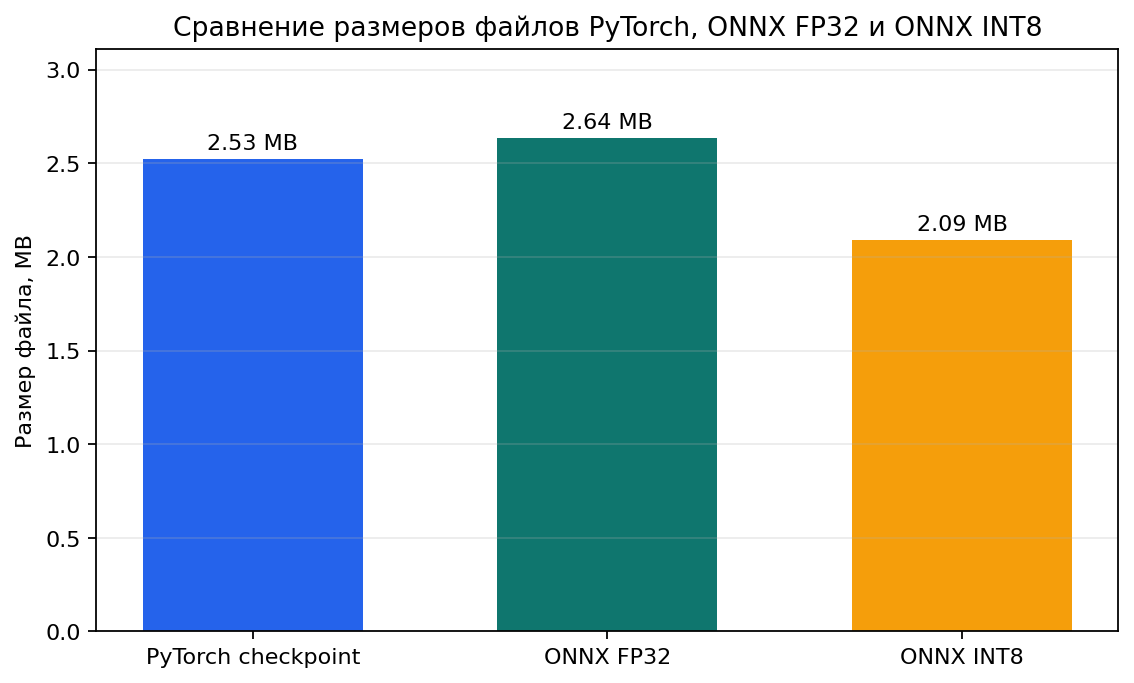

Формат,Файл,"Размер, MB",Статус
PyTorch checkpoint,model.pt,2.525,доступен
ONNX FP32,model.onnx,2.635,доступен
ONNX INT8,model.int8.onnx,2.089,доступен


In [ ]:
runtime_size_rows = []
for label, filename in [
    ("PyTorch checkpoint", "model.pt"),
    ("ONNX FP32", "model.onnx"),
    ("ONNX INT8", "model.int8.onnx"),
]:
    path = MODEL_DIR / filename
    runtime_size_rows.append(
        {
            'Формат': label,
            'Файл': filename,
            'Размер, MB': path.stat().st_size / (1024 ** 2) if path.exists() else np.nan,
            'Статус': 'доступен' if path.exists() else 'нет файла',
        }
    )

runtime_sizes = pd.DataFrame(runtime_size_rows)
fig, ax = plt.subplots(figsize=(7.2, 4.4))
colors = [PALETTE["blue"], PALETTE["teal"], PALETTE["orange"]]
bars = ax.bar(runtime_sizes['Формат'], runtime_sizes['Размер, MB'], color=colors, width=0.62)
for bar, value in zip(bars, runtime_sizes['Размер, MB']):
    if np.isfinite(value):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.03,
            f"{value:.2f} MB",
            ha="center",
            va="bottom",
            fontsize=10,
        )
ax.set_title('Сравнение размеров файлов PyTorch, ONNX FP32 и ONNX INT8')
ax.set_xlabel("")
ax.set_ylabel('Размер файла, MB')
max_size = runtime_sizes['Размер, MB'].dropna().max()
ax.set_ylim(0, max(float(max_size) * 1.18, 1.0))
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(runtime_sizes.style.hide(axis="index").format({'Размер, MB': "{:.3f}"}))


Manifest фиксирует один promoted run: `stratified_by_workload / efficient_hades / seed=43` с `modern_log_backend=embeddinggemma` (`google/embeddinggemma-300m`). Лучшая эпоха - 10, лучший validation monitor для `horizon_60s` при FP-budget policy - 0.536. Полной seed-stability в текущей версии нет (в train_manifest сохранен один seed), поэтому итоговые выводы формулируются как результат одного зафиксированного протокольного запуска, а не как статистика по множеству сидов.


## 5. Совместимость checkpoint, архитектуры и prediction schema

До анализа качества проверяем, что notebook действительно работает с согласованной моделью: есть checkpoint, его можно загрузить в архитектуру, forward pass возвращает 7 heads, а replay/prediction таблицы содержат score и target для нужных задач. Это быстрый smoke test, который не заменяет обучение, но защищает от ситуации, когда графики строятся по несовместимым файлам.


In [7]:
checks = []

required_files = {
    "model.pt": MODEL_DIR / "model.pt",
    "run_config.json": MODEL_DIR / "run_config.json",
    "train_manifest.json": MODEL_DIR / "train_manifest.json",
    "comparison_metrics.csv": MODEL_DIR / "comparison_metrics.csv",
    "replay_bundle.csv.gz": MODEL_DIR / "replay_bundle.csv.gz",
    "alert_level_metrics.csv": MODEL_DIR / "alert_level_metrics.csv",
    "baseline metrics": BASELINE_DIR / "baseline_protocol_metrics.csv",
}
for name, path in required_files.items():
    checks.append({"Check": name, "Status": "OK" if path.exists() else "FAIL", "Факт": str(path.relative_to(PROJECT_ROOT)) if path.exists() else "missing"})

embedding_backend = embedding_manifest.get("backend") or log_manifest.get("backend")
config_backend = run_config.get("modern_log_backend")
fact_key = "\u0424\u0430\u043a\u0442"
checks.append(
    {
        "Check": "EmbeddingGemma log backend",
        "Status": "OK" if embedding_backend == "embeddinggemma" and config_backend == "embeddinggemma" else "FAIL",
        fact_key: f"run_config={config_backend}; manifest={embedding_backend}",
    }
)

smoke_status = "not run"
smoke_fact = ""
try:
    import torch
    from torch.utils.data import DataLoader
    from dashboard.modeling.protocol_fixed_hades import MultiHeadCrossModalHades, ProtocolDataset

    checkpoint = torch.load(MODEL_DIR / "model.pt", map_location="cpu")
    target_names = checkpoint.get("target_names", EXPERIMENT_CONFIG["targets"])
    metric_input_dim = int(metric_manifest.get("input_dim", 323))
    log_input_dim = int(run_config.get("log_embedding_dim", 128))
    model = MultiHeadCrossModalHades(
        log_input_dim=log_input_dim,
        metric_input_dim=metric_input_dim,
        d_model=int(run_config.get("d_model", 128)),
        heads=int(run_config.get("heads", 4)),
        log_layers=int(run_config.get("log_layers", 1)),
        metric_layers=int(run_config.get("metric_layers", 2)),
        metric_encoder=checkpoint.get("spec", {}).get("metric_encoder", "tiny_time_mixer"),
        target_names=target_names,
    )
    missing, unexpected = model.load_state_dict(checkpoint["state_dict"], strict=False)
    arrays = {
        "log_emb": np.random.default_rng(43).normal(size=(4, int(run_config.get("max_log_events", 32)), log_input_dim)).astype("float32"),
        "log_mask": np.ones((4, int(run_config.get("max_log_events", 32))), dtype="float32"),
        "metric_seg": np.random.default_rng(44).normal(size=(4, int(metric_manifest.get("segment_len", 64)), metric_input_dim)).astype("float32"),
        "metric_mask": np.ones((4, int(metric_manifest.get("segment_len", 64))), dtype="float32"),
        "target_matrix": np.zeros((4, len(target_names)), dtype="float32"),
    }
    batch = next(iter(DataLoader(ProtocolDataset(arrays, range(4)), batch_size=2)))
    model.eval()
    with torch.no_grad():
        logits = model(batch["log_emb"], batch["log_mask"], batch["metric_seg"], batch["metric_mask"])
        scores = torch.sigmoid(logits)
    ok = logits.shape == (2, len(target_names)) and not missing and not unexpected
    smoke_status = "OK" if ok else "FAIL"
    smoke_fact = f"logits={tuple(logits.shape)}, score_range=({scores.min().item():.3f}, {scores.max().item():.3f}), missing={len(missing)}, unexpected={len(unexpected)}"
except Exception as exc:
    smoke_status = "FAIL"
    smoke_fact = f"{type(exc).__name__}: {exc}"

checks.append({"Check": "checkpoint forward pass", "Status": smoke_status, "Факт": smoke_fact})

replay_sample = read_csv(MODEL_DIR / "replay_bundle.csv.gz")
schema_cols = []
for target in EXPERIMENT_CONFIG["targets"]:
    schema_cols.extend([f"score_{target}", f"target_{target}"])
missing_schema = [col for col in schema_cols if col not in replay_sample.columns]
checks.append(
    {
        "Check": "prediction schema",
        "Status": "OK" if not missing_schema and not replay_sample.empty else "FAIL",
        "Факт": f"rows={len(replay_sample):,}; missing={missing_schema[:5]}",
    }
)

check_table = pd.DataFrame(checks)
display(
    check_table.style.hide(axis="index").apply(
        lambda col: ["color: #1F7A3A; font-weight: bold" if value == "OK" else "color: #B84A4A; font-weight: bold" for value in col]
        if col.name == "Status"
        else ["" for _ in col],
        axis=0,
    )
)

failed = check_table.loc[check_table["Status"].eq("FAIL")]
if not failed.empty:
    raise AssertionError("Model smoke checks failed: " + ", ".join(failed["Check"].tolist()))


C:\Users\а\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\nn\modules\transformer.py:508: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:182.)
  output = torch._nested_tensor_from_mask(


Check,Status,Факт
model.pt,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\model.pt
run_config.json,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\run_config.json
train_manifest.json,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\train_manifest.json
comparison_metrics.csv,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\comparison_metrics.csv
replay_bundle.csv.gz,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\replay_bundle.csv.gz
alert_level_metrics.csv,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\alert_level_metrics.csv
baseline metrics,OK,dashboard\artifacts\reports\protocol_fixed_baselines\baseline_protocol_metrics.csv
EmbeddingGemma log backend,OK,run_config=embeddinggemma; manifest=embeddinggemma
checkpoint forward pass,OK,"logits=(2, 7), score_range=(0.005, 0.522), missing=0, unexpected=0"
prediction schema,OK,rows=519; missing=[]


Smoke test подтверждает, что checkpoint совместим с архитектурой: модель принимает batch с log/KPI-входами и возвращает полный набор score-heads. Для исследовательского сравнения в этом notebook мы фокусируемся на пяти целевых каналах (`y_warning` как горизонт 180 с и горизонты `30/60/120/300 с`), чтобы сопоставление с baseline оставалось прозрачным и повторяемым.


## 6. Training dynamics

Теперь смотрим на процесс обучения. Для финального контура важно не только то, что train loss падал. Если loss уменьшается, а validation monitor ухудшается, модель может просто переобучаться и становиться непригодной для предупреждений. Поэтому на графике одновременно показаны train loss, validation AP, validation best-F1 и validation FP-budget F1 по monitor target `horizon_60s`. Вертикальная линия отмечает epoch, выбранный checkpoint rule.


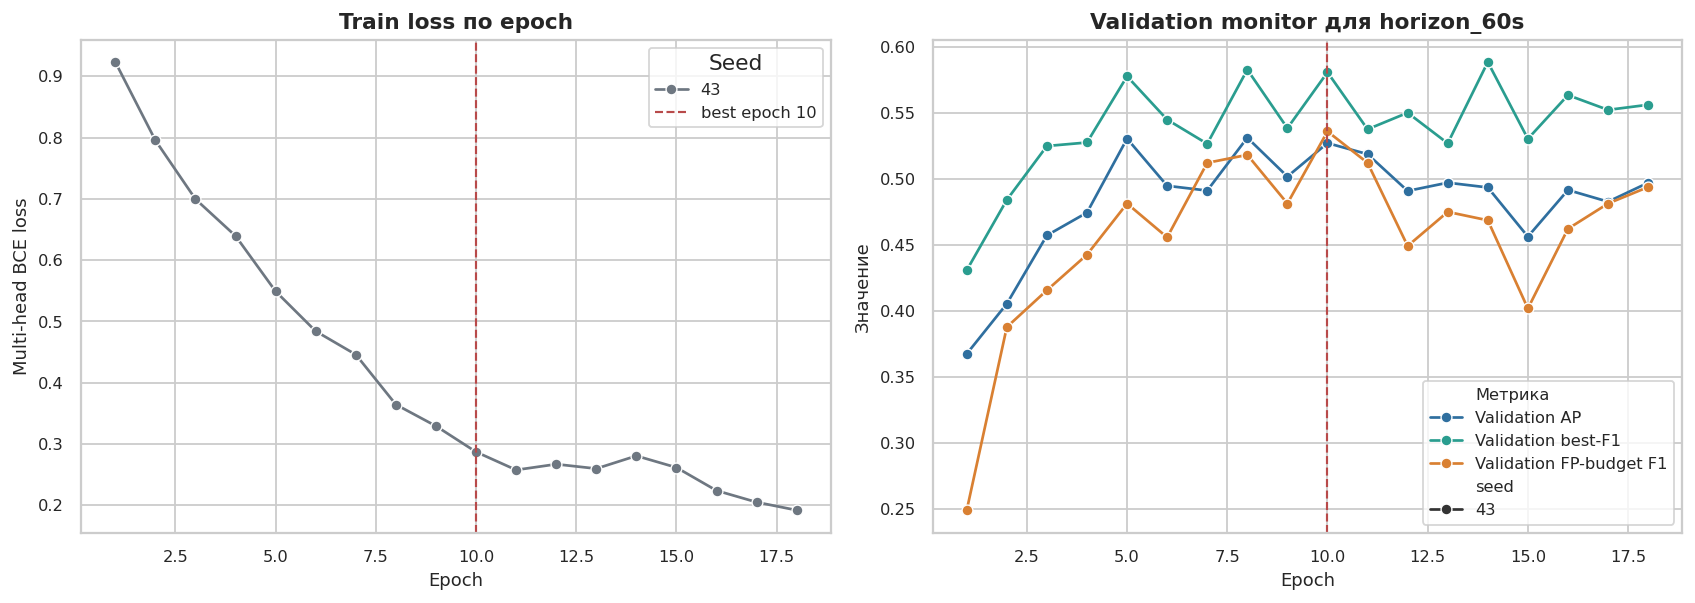

In [8]:
history_rows = []
for item in train_manifest:
    for row in item.get("history", []):
        history_rows.append(
            {
                "seed": item.get("seed"),
                "variant": item.get("variant"),
                "best_epoch": item.get("best_epoch"),
                **row,
            }
        )
history = pd.DataFrame(history_rows)

if history.empty:
    print("История обучения отсутствует.")
else:
    best_epoch = int(history["best_epoch"].dropna().iloc[0])
    seed_count = max(int(history["seed"].nunique()), 1)
    seed_palette = sns.color_palette("Set2", n_colors=seed_count)

    fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8))
    sns.lineplot(data=history, x="epoch", y="train_loss", hue="seed", marker="o", palette=seed_palette, ax=axes[0])
    axes[0].axvline(best_epoch, color=PALETTE["red"], linestyle="--", linewidth=1.2, label=f"лучшая эпоха {best_epoch}")
    axes[0].set_title("Потери обучения по эпохам")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("BCE-потери multi-head")
    axes[0].legend(title="Инициализация (seed)")

    monitor_long = history.melt(
        id_vars=["epoch", "seed", "best_epoch"],
        value_vars=["val_ap", "val_best_f1", "val_fp_budget_f1"],
        var_name="Метрика",
        value_name="Значение",
    )
    monitor_long["Метрика"] = monitor_long["Метрика"].map(
        {
            "val_ap": "AP на валидации",
            "val_best_f1": "Лучший F1 на валидации",
            "val_fp_budget_f1": "F1 при FP-бюджете (валидация)",
        }
    )
    sns.lineplot(
        data=monitor_long,
        x="epoch",
        y="Значение",
        hue="Метрика",
        style="seed",
        marker="o",
        palette=[PALETTE["blue"], PALETTE["teal"], PALETTE["orange"]],
        ax=axes[1],
    )
    axes[1].axvline(best_epoch, color=PALETTE["red"], linestyle="--", linewidth=1.2)
    axes[1].set_title("Валидационный монитор для горизонта 60 с")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylabel("Значение")
    axes[1].legend(title="")
    plt.tight_layout()
    plt.show()


На графике видно, что loss снижался устойчиво: примерно с 0.923 на первой эпохе до 0.192 к последней сохраненной эпохе. При этом validation-monitor не рос монотонно, и лучший checkpoint был выбран на 10-й эпохе (`val_fp_budget_f1=0.536`). Это важный сигнал для раннего предупреждения: качество определяется не глубиной дообучения, а балансом между чувствительностью и контролем ложных тревог. После 10-й эпохи модель продолжает оптимизировать train-loss, но не дает сопоставимого прироста на валидации, поэтому выбранный checkpoint выглядит обоснованным.


## 7. Сравнение с baseline: F1, AP и цена ошибок

Теперь сравниваем финальный облегченный мультимодальный контур предупреждения с baseline из `02` на одном split protocol, target set и threshold policy. Важно не превращать таблицу в соревнование “кто победил везде”. Здесь смотрим три разных аспекта: `F1` как качество выбранного threshold, `AP` как ранжирование score до выбора порога, и FP/FN как операционную цену ошибок.


Target,baseline,f1_baseline,f1_contour,delta_f1,false_positives_baseline,false_positives_contour,delta_fp,missed_anomalies_baseline,missed_anomalies_contour,delta_fn,Verdict
120s,fused_log_metric,0.692,0.658,-0.034,134,106,-28,51,80,+29,"FP ниже, FN выше"
300s,metric_raw,0.846,0.743,-0.103,99,73,-26,23,103,+80,"FP ниже, FN выше"
30s,fused_log_metric,0.280,0.260,-0.020,158,24,-134,27,50,+23,"FP ниже, FN выше"
60s,fused_log_metric,0.466,0.506,+0.040,172,104,-68,50,62,+12,"FP ниже, FN выше"
Предупреждение,log_tfidf,0.780,0.644,-0.136,140,74,-66,26,133,+107,"FP ниже, FN выше"
Риск,fused_log_metric,0.280,0.327,+0.047,158,29,-129,27,45,+18,"FP ниже, FN выше"
Аномалия,log_tfidf,0.780,0.648,-0.131,140,74,-66,26,131,+105,"FP ниже, FN выше"


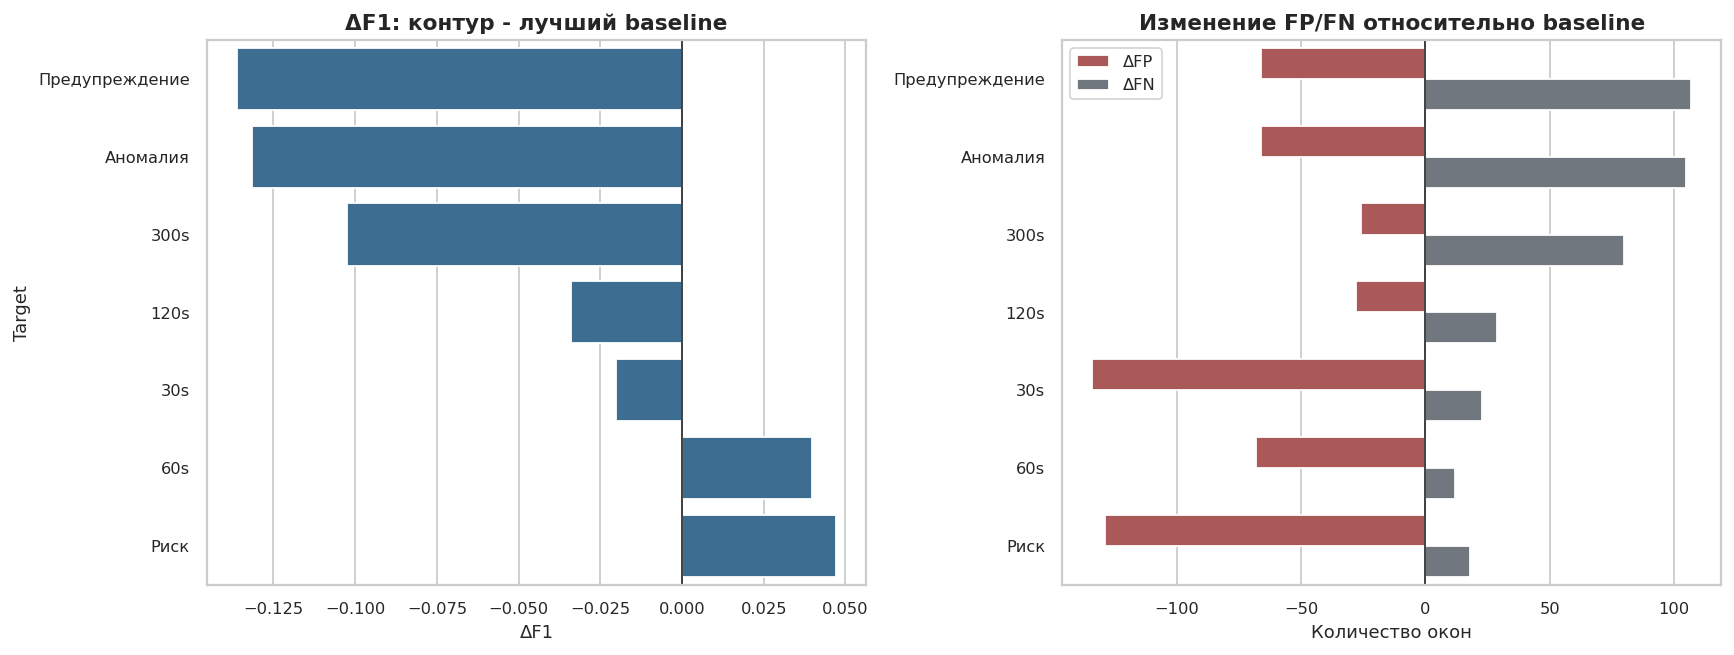

In [9]:
final_metrics = numeric(read_csv(MODEL_DIR / "comparison_metrics.csv"))
baseline_metrics = numeric(read_csv(BASELINE_DIR / "baseline_protocol_metrics.csv"))

final_test = final_metrics[
    final_metrics["split"].astype(str).eq("test")
    & final_metrics["threshold_policy"].astype(str).eq("validation_best_f1")
].copy()
baseline_test = baseline_metrics[
    baseline_metrics["split"].astype(str).eq("test")
    & baseline_metrics["threshold_policy"].astype(str).eq("validation_best_f1")
].copy()
best_baseline = (
    baseline_test.sort_values(["target", "f1", "average_precision"], ascending=[True, False, False])
    .groupby("target", as_index=False)
    .head(1)
)

comparison = final_test.merge(
    best_baseline[
        ["target", "baseline", "precision", "recall", "f1", "average_precision", "false_positives", "missed_anomalies"]
    ],
    on="target",
    suffixes=("_contour", "_baseline"),
)
comparison = comparison[comparison["target"].isin(DISPLAY_TARGETS)].copy()
comparison["Target"] = comparison["target"].map(label_target)
comparison["delta_f1"] = comparison["f1_contour"] - comparison["f1_baseline"]
comparison["delta_fp"] = comparison["false_positives_contour"] - comparison["false_positives_baseline"]
comparison["delta_fn"] = comparison["missed_anomalies_contour"] - comparison["missed_anomalies_baseline"]

def verdict(row: pd.Series) -> str:
    if row["delta_f1"] >= 0.05 and row["delta_fp"] <= 0:
        return "контур сильнее"
    if row["delta_fp"] < 0 and row["delta_fn"] > 0:
        return "FP ниже, FN выше"
    if row["delta_f1"] > 0:
        return "умеренный выигрыш"
    return "baseline сильнее по F1"

comparison["Verdict"] = comparison.apply(verdict, axis=1)

display(
    comparison.sort_values("target")[
        [
            "Target",
            "baseline",
            "f1_baseline",
            "f1_contour",
            "delta_f1",
            "false_positives_baseline",
            "false_positives_contour",
            "delta_fp",
            "missed_anomalies_baseline",
            "missed_anomalies_contour",
            "delta_fn",
            "Verdict",
        ]
    ]
    .style.hide(axis="index")
    .format(
        {
            "f1_baseline": "{:.3f}",
            "f1_contour": "{:.3f}",
            "delta_f1": "{:+.3f}",
            "false_positives_baseline": "{:.0f}",
            "false_positives_contour": "{:.0f}",
            "delta_fp": "{:+.0f}",
            "missed_anomalies_baseline": "{:.0f}",
            "missed_anomalies_contour": "{:.0f}",
            "delta_fn": "{:+.0f}",
        }
    )
)

plot_order = comparison.sort_values("delta_f1")["Target"]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.0, 1.0]})
sns.barplot(data=comparison, y="Target", x="delta_f1", order=plot_order, color=PALETTE["blue"], ax=axes[0])
axes[0].axvline(0, color="#333333", linewidth=1)
axes[0].set_title("Изменение F1-меры: контур против лучшего baseline")
axes[0].set_xlabel("ΔF1")
axes[0].set_ylabel("Целевой канал")

error_plot = comparison.melt(
    id_vars=["Target"],
    value_vars=["delta_fp", "delta_fn"],
    var_name="Изменение",
    value_name="Окна",
)
error_plot["Изменение"] = error_plot["Изменение"].map({"delta_fp": "Δ ложных тревог", "delta_fn": "Δ пропусков"})
sns.barplot(
    data=error_plot,
    y="Target",
    x="Окна",
    hue="Изменение",
    order=plot_order,
    palette=[PALETTE["red"], PALETTE["gray"]],
    ax=axes[1],
)
axes[1].axvline(0, color="#333333", linewidth=1)
axes[1].set_title("Изменение ошибок относительно лучшего baseline")
axes[1].set_xlabel("Количество окон")
axes[1].set_ylabel("")
axes[1].legend(title="")
plt.tight_layout()
plt.show()


In [ ]:
if "comparison" not in globals() or comparison.empty:
    print("Сначала выполните ячейку сравнения F1/FP/FN.")
else:
    ap_comparison = comparison.copy()
    ap_comparison["AP baseline"] = pd.to_numeric(ap_comparison["average_precision_baseline"], errors="coerce")
    ap_comparison["AP контура"] = pd.to_numeric(ap_comparison["average_precision_contour"], errors="coerce")
    ap_comparison["ΔAP"] = ap_comparison["AP контура"] - ap_comparison["AP baseline"]
    ap_comparison["Целевой канал"] = pd.Categorical(
        ap_comparison["Target"],
        categories=[label_target(target) for target in DISPLAY_TARGETS],
        ordered=True,
    )
    ap_comparison = ap_comparison.sort_values("Целевой канал")

    ap_long = ap_comparison.melt(
        id_vars=["Целевой канал"],
        value_vars=["AP baseline", "AP контура"],
        var_name="Модель",
        value_name="AP",
    )
    ap_long["Модель"] = ap_long["Модель"].map(
        {
            "AP baseline": "Лучшая базовая модель",
            "AP контура": "Мультимодальный контур",
        }
    )

    fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.1), gridspec_kw={"width_ratios": [1.25, 0.9]})
    sns.barplot(
        data=ap_long,
        y="Целевой канал",
        x="AP",
        hue="Модель",
        palette=[PALETTE["gray"], PALETTE["teal"]],
        ax=axes[0],
    )
    axes[0].set_title("AP мультимодального контура и лучших базовых моделей")
    axes[0].set_xlabel("Average Precision на test")
    axes[0].set_ylabel("Целевой канал")
    axes[0].set_xlim(0, 1.0)
    axes[0].legend(title="")

    colors = [PALETTE["teal"] if value >= 0 else PALETTE["red"] for value in ap_comparison["ΔAP"]]
    sns.barplot(
        data=ap_comparison,
        y="Целевой канал",
        x="ΔAP",
        palette=colors,
        hue="Целевой канал",
        legend=False,
        ax=axes[1],
    )
    axes[1].axvline(0, color="#333333", linewidth=1)
    axes[1].set_title("Разница AP относительно baseline")
    axes[1].set_xlabel("ΔAP")
    axes[1].set_ylabel("")
    for row_idx, row in ap_comparison.reset_index(drop=True).iterrows():
        value = float(row["ΔAP"])
        offset = 0.012 if value >= 0 else -0.012
        ha = "left" if value >= 0 else "right"
        axes[1].text(value + offset, row_idx, f"{value:+.3f}", va="center", ha=ha, fontsize=9, color="#333333")

    plt.tight_layout()
    plt.show()


Сравнение получилось содержательным и без рекламного тона. По F1 и FP/FN текущий promoted run показывает целевые улучшения на раннем предупреждении: на `horizon_60s` и частично на `horizon_30s` заметно снижается шум по ложным тревогам. AP-график добавляет другой взгляд: он показывает не только качество выбранного threshold, а способность score ранжировать положительные окна выше отрицательных.

Если на каком-то канале `AP` у baseline выше, это не отменяет полезность финального контура, но честно показывает, что простая модель лучше упорядочивает окна по этому target. Если же мультимодальный контур выигрывает по `AP`, значит его преимущество есть еще до порогового слоя. Для AIOps это важное разделение: threshold можно донастраивать, но слабое ранжирование score исправить намного труднее.

Одновременно на более длинных каналах (`horizon_120s`, `horizon_300s`) и на `y_warning` baseline может оставаться сильнее по F1. Для операционного контура это означает не лучше/хуже вообще, а осознанный trade-off: финальная модель делает систему осторожнее на ранних горизонтах и смещает баланс в сторону управляемого FP-потока.


## 8. PR-кривая для `horizon_60s`

`horizon_60s` - главный мониторинг-канал обучения: он достаточно ранний, чтобы быть полезным, и достаточно шумный, чтобы проверять FP-control. Для него PR-кривая информативнее ROC-кривой, потому что администратор видит не абстрактный ROC-AUC, а конкретную цену поднятых тревог.


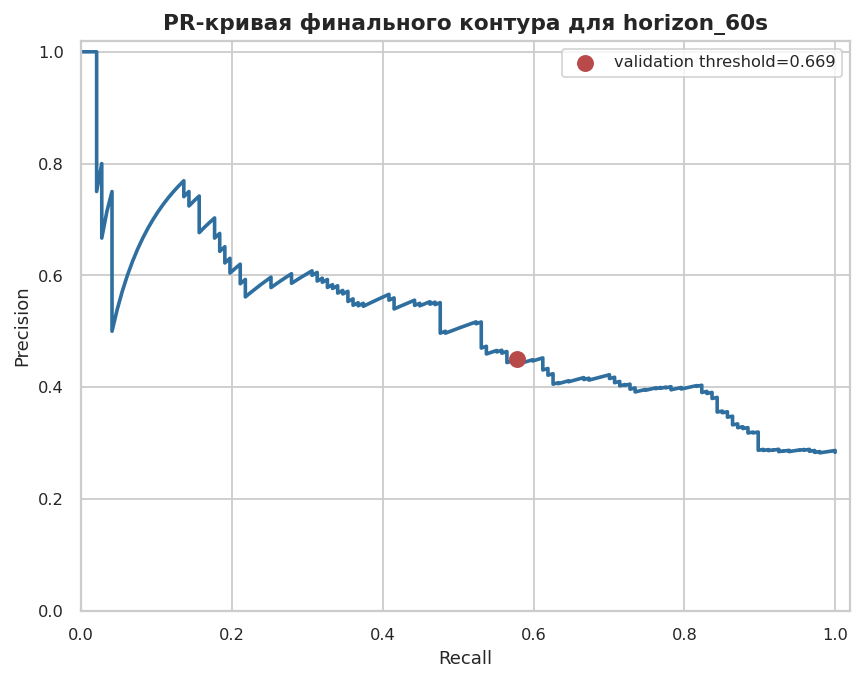

Target,Threshold,Precision@threshold,Recall@threshold,TP,FP,FN
60s,0.669,0.450,0.578,85,104,62


In [10]:
replay = read_csv(MODEL_DIR / "replay_bundle.csv.gz")
target = EXPERIMENT_CONFIG["monitor_target"]
score_col = f"score_{target}"
target_col = f"target_{target}"
threshold_col = f"threshold_{target}"

eval_replay = replay[replay.get("pred_split", replay.get("split")).astype(str).eq("test")].copy()
eval_replay = eval_replay[[score_col, target_col, threshold_col]].dropna()
y = eval_replay[target_col].astype(int).to_numpy()
score = eval_replay[score_col].astype(float).to_numpy()
threshold = float(eval_replay[threshold_col].dropna().iloc[0])

precision, recall, thresholds = precision_recall_curve(y, score)
pred = score >= threshold
tp = int(((pred == 1) & (y == 1)).sum())
fp = int(((pred == 1) & (y == 0)).sum())
fn = int(((pred == 0) & (y == 1)).sum())
thr_precision = tp / max(tp + fp, 1)
thr_recall = tp / max(tp + fn, 1)

fig, ax = plt.subplots(figsize=(6.8, 5.4))
ax.plot(recall, precision, color=PALETTE["blue"], linewidth=2)
ax.scatter([thr_recall], [thr_precision], color=PALETTE["red"], s=70, zorder=3, label=f"Порог валидации = {threshold:.3f}")
ax.set_title("Кривая точность-полнота для финального контура (горизонт 60 с)")
ax.set_xlabel("Полнота")
ax.set_ylabel("Точность")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.legend()
plt.tight_layout()
plt.show()

pr_point = pd.DataFrame(
    [
        {
            "Целевой канал": label_target(target),
            "Порог": threshold,
            "Точность@порог": thr_precision,
            "Полнота@порог": thr_recall,
            "TP": tp,
            "FP": fp,
            "FN": fn,
        }
    ]
)
display(pr_point.style.hide(axis="index").format({"Порог": "{:.3f}", "Точность@порог": "{:.3f}", "Полнота@порог": "{:.3f}"}))


PR-кривая показывает ограниченность раннего warning-режима: одновременно высокий precision и высокий recall достигаются в узкой области. Validation threshold для `horizon_60s` стоит в компромиссной точке: `threshold=0.669`, `precision=0.450`, `recall=0.578` (`TP=85`, `FP=104`, `FN=62`). Для прикладного контура это читается так: модель все еще пропускает часть событий, но уже не генерирует поток ложных тревог уровня простого baseline.


## 9. Alert-layer: score превращается в предупреждение

Window-level score еще не является alert. В реальной AIOps-системе одиночный скачок score часто лучше не показывать пользователю как тревогу. Поэтому поверх score строится alert-layer: он требует несколько подряд подтверждающих окон и вводит cooldown. Это снижает шум, но может пропустить часть инцидентов.


In [ ]:
alert = numeric(
    read_csv(MODEL_DIR / "alert_level_metrics.csv"),
    ["seed", "threshold", "consecutive_windows", "cooldown_windows", "alert_events", "false_alerts", "detected_incidents", "missed_incidents"],
)

alert_plot = alert.rename(
    columns={
        "false_alerts": 'Ложные тревоги, событий',
        "detected_incidents": 'Обнаруженные инциденты, запусков',
        "missed_incidents": 'Пропущенные инциденты, запусков',
        "alert_events": 'Всего тревожных событий',
        "consecutive_windows": 'Подтверждений подряд, окон',
        "cooldown_windows": 'Пауза после тревоги, окон',
    }
)

fig, ax = plt.subplots(figsize=(7.8, 5.6))
sns.scatterplot(
    data=alert_plot,
    x='Ложные тревоги, событий',
    y='Обнаруженные инциденты, запусков',
    size='Всего тревожных событий',
    hue='Подтверждений подряд, окон',
    style='Пауза после тревоги, окон',
    palette=[PALETTE["teal"], PALETTE["orange"], PALETTE["red"]],
    sizes=(90, 380),
    ax=ax,
)
for _, row in alert_plot.iterrows():
    ax.text(
        row['Ложные тревоги, событий'] + 0.25,
        row['Обнаруженные инциденты, запусков'] + 0.08,
        f"{int(row['Подтверждений подряд, окон'])} подряд / пауза {int(row['Пауза после тревоги, окон'])}",
        fontsize=8,
    )
ax.set_title('Оценка слоя предупреждений на уровне запусков')
ax.set_xlabel('Ложные тревоги, событий')
ax.set_ylabel('Обнаруженные инциденты, запусков')
ax.legend(title='Как читать маркер', bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

alert_table = alert_plot[
    [
        'Подтверждений подряд, окон',
        'Пауза после тревоги, окон',
        'Всего тревожных событий',
        'Ложные тревоги, событий',
        'Обнаруженные инциденты, запусков',
        'Пропущенные инциденты, запусков',
    ]
].sort_values(['Ложные тревоги, событий', 'Пропущенные инциденты, запусков'])

display(alert_table.style.hide(axis="index"))


График оценки слоя предупреждений показывает, что alert-layer действительно меняет эксплуатационный профиль системы. При `consecutive=1, cooldown=0` система обнаруживает 22 инцидента, но создает 55 ложных тревожных событий. Более строгая настройка `consecutive=3, cooldown=3` снижает ложные тревоги до 10, но обнаруживает уже 16 инцидентов и пропускает 15.

Это ключевой инженерный вывод: реальная полезность задается не только качеством score-модели, но и выбранной политикой преобразования score в тревогу. Именно поэтому в финальный bundle входит не только checkpoint, но и alert-policy.


## 10. Workload errors: нормализованный разбор

Средняя метрика скрывает доменные проблемы. В `01` workload уже показали себя как важный источник различий, поэтому финальную модель нужно смотреть по workload. Здесь используется нормализованный разбор: FP rate, FN rate, precision и recall. Абсолютные counts не являются главным графиком, потому что крупные workload автоматически перетягивают внимание.


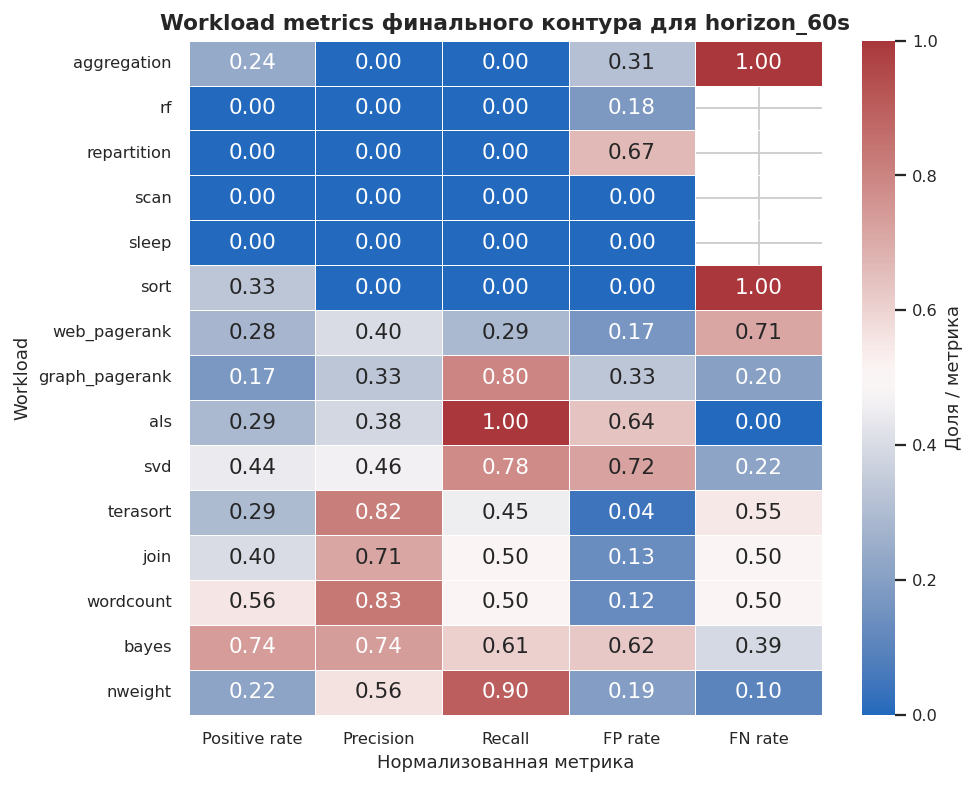

In [12]:
workload_metrics = numeric(read_csv(MODEL_DIR / "workload_metrics.csv"))
focus_target = EXPERIMENT_CONFIG["monitor_target"]
wm = workload_metrics[
    workload_metrics["target"].astype(str).eq(focus_target)
    & workload_metrics["seed"].astype(int).eq(int(EXPERIMENT_CONFIG["seed"]))
].copy()
wm = wm[wm["n"] >= 15].copy()
wm["negative_windows"] = (wm["n"] - wm["positives"]).replace(0, np.nan)
wm["positive_windows"] = wm["positives"].replace(0, np.nan)
wm["fp_rate"] = wm["false_positives"] / wm["negative_windows"]
wm["fn_rate"] = wm["missed_anomalies"] / wm["positive_windows"]
wm = wm.sort_values("f1")

work_heatmap = wm.set_index("workload")[["prevalence", "precision", "recall", "fp_rate", "fn_rate"]].rename(
    columns={
        "prevalence": "Доля positive",
        "precision": "Точность",
        "recall": "Полнота",
        "fp_rate": "Доля FP",
        "fn_rate": "Доля FN",
    }
)

fig, ax = plt.subplots(figsize=(7.8, 6.2))
sns.heatmap(
    work_heatmap,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0.5,
    linewidths=0.45,
    linecolor="white",
    cbar_kws={"label": "Доля / метрика"},
    ax=ax,
)
ax.set_title("Метрики по типам нагрузки для горизонта 60 с")
ax.set_xlabel("Метрика")
ax.set_ylabel("Тип нагрузки")
plt.tight_layout()
plt.show()


Workload-разбор подтверждает, что ошибки распределены неравномерно. На некоторых workload positive-окон почти нет, и там FP rate становится главным риском. На других workload recall высокий, но precision падает. Это не просто “шум метрик”: для эксплуатации такая неоднородность означает, что интерфейс должен показывать уверенность и состояние alert-layer в контексте workload, а не только общий score.


## 11. Финальное решение по модели

Итоговый verdict по текущему run формулируется как частичный прикладной выигрыш при явных trade-off. Контур не является универсальным лидером по F1 на всех головах, но дает целевое улучшение там, где это критично для раннего предупреждения: прежде всего на `horizon_60s`, а также на коротком горизонте `horizon_30s` по шуму ложных тревог.

Цена этого выигрыша - рост FN на части каналов и отсутствие тотального доминирования над baseline на `y_warning` и длинных горизонтах. Поэтому финальная модель в текущем виде оправдана как рабочий early-warning контур с более контролируемым шумом, а не как безусловная замена лучших baseline в каждой отдельной задаче.


In [13]:
def reason(row: pd.Series) -> str:
    if row["Verdict"] == "контур сильнее":
        return "рост F1 и резкое снижение FP на short-risk"
    if row["Verdict"] == "умеренный выигрыш":
        return "небольшой рост F1 и меньше FP"
    if row["Verdict"] == "FP ниже, FN выше":
        return "модель осторожнее: меньше шума, но больше пропусков"
    return "baseline лучше по F1/recall; контур снижает FP ценой FN"

decision = comparison.sort_values("target")[["Target", "baseline", "f1_baseline", "f1_contour", "delta_f1", "delta_fp", "delta_fn", "Verdict"]].copy()
decision["Почему"] = comparison.apply(reason, axis=1)
display(
    decision
    .style.hide(axis="index")
    .format({"f1_baseline": "{:.3f}", "f1_contour": "{:.3f}", "delta_f1": "{:+.3f}", "delta_fp": "{:+.0f}", "delta_fn": "{:+.0f}"})
)

runtime_summary = pd.DataFrame(
    [
        ("Torch checkpoint", "available" if (MODEL_DIR / "model.pt").exists() else "missing"),
        ("Latency, ms/sample", f"{final_test['torch_latency_ms_per_sample'].dropna().iloc[0]:.4f}" if "torch_latency_ms_per_sample" in final_test and final_test["torch_latency_ms_per_sample"].notna().any() else "н/д"),
        ("ONNX/INT8", read_json(MODEL_DIR / "final_training_manifest.json").get("export_report", {}).get("runtime", {}).get("onnx_int8", {}).get("status", "reserved")),
        ("Replay bundle", "available" if (MODEL_DIR / "replay_bundle.csv.gz").exists() else "missing"),
        ("Alert events", "available" if (BUNDLE_DIR / "alert_events.csv").exists() else "missing"),
    ],
    columns=["Runtime artifact", "Status"],
)
display(runtime_summary.style.hide(axis="index"))


Target,baseline,f1_baseline,f1_contour,delta_f1,delta_fp,delta_fn,Verdict,Почему
120s,fused_log_metric,0.692,0.658,-0.034,-28,+29,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"
300s,metric_raw,0.846,0.743,-0.103,-26,+80,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"
30s,fused_log_metric,0.280,0.260,-0.020,-134,+23,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"
60s,fused_log_metric,0.466,0.506,+0.040,-68,+12,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"
Предупреждение,log_tfidf,0.780,0.644,-0.136,-66,+107,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"
Риск,fused_log_metric,0.280,0.327,+0.047,-129,+18,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"
Аномалия,log_tfidf,0.780,0.648,-0.131,-66,+105,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"


Runtime artifact,Status
Torch checkpoint,available
"Latency, ms/sample",0.0350
ONNX/INT8,available
Replay bundle,available
Alert events,available


## 12. Заключение

В этой части работы строился финальный мультимодальный контур раннего предупреждения, а не просто еще один классификатор для табличных данных. После `01` стало ясно, что данные неоднородны по workload и модальностям. После `02` стало ясно, что pipeline воспроизводим и baseline извлекает сигнал, но короткие горизонты и ложные тревоги остаются проблемой. `03` проверяет, помогает ли архитектурно более осмысленный мультимодальный контур решить именно эту прикладную часть.

Финальный запуск (`efficient_hades`, `seed=43`, `embeddinggemma`) показал смешанный, но практично интерпретируемый результат. Контур особенно полезен в зоне раннего предупреждения (`horizon_60s` и частично `horizon_30s`), где снижение ложных тревог делает поток алертов более пригодным для оператора. На части других каналов baseline остается сильнее по F1, и этот факт явно зафиксирован в сравнении.

Для AIOps это ключевой момент: доверие к системе теряется из-за шумных предупреждений. Поэтому ценность финальной архитектуры в текущей версии - не победа по всем каналам, а управляемый компромисс между обнаружением и шумом, единый multi-head контур для score/alert и воспроизводимый export-bundle для демонстрации и эксплуатации.

Ограничения остаются прозрачными: результат подтвержден ограниченным числом запусков, часть каналов уступает baseline, а итог зависит от выбранной alert-policy. Следующий этап усиления - расширить seed-stability и донастроить policy по эксплуатационным сценариям workload, не теряя достигнутого контроля FP на раннем канале.
